split
random    0.999605
block     0.998904
unseen    0.007780
Name: metrics.attack_recall, dtype: float64
            n_attack_test  xgb_recall_at_1pct_FPR  iso_recall_at_1pct_FPR
held_out                                                                 
BruteForce          13832                   0.289                   0.000
DoS                251711                   0.684                   0.271
Web                  2159                   0.952                   0.000
Rare                   68                   0.441                   0.279
PortScan           158804                   0.011                   0.000
Bot                  1956                   0.015                   0.000
DDoS               128025                   0.645                   0.083


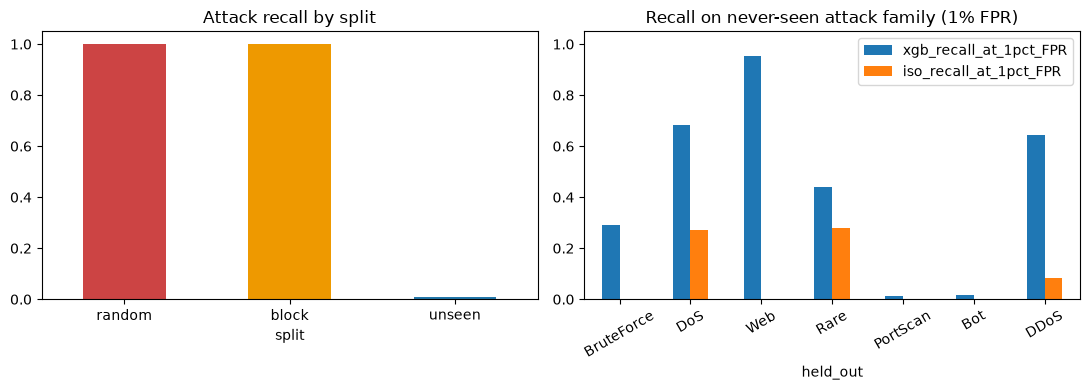

In [2]:
from pathlib import Path
import mlflow, pandas as pd, matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
mlflow.set_tracking_uri(f"sqlite:///{(ROOT / 'mlflow.db').resolve().as_posix()}")
runs = mlflow.search_runs(experiment_names=["intrusion_baseline"])
if runs.empty:
    raise RuntimeError("No intrusion_baseline runs found. Run ml.train_intrusion first.")
runs["split"] = runs["params.split"]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# chart 1: same model, three splits
s = (runs[runs["params.with_port"] == "False"]
     .groupby("split")["metrics.attack_recall"].max()
     .reindex(["random", "block", "unseen"]))
print(s)                                   # check the numbers before trusting the chart
s.plot.bar(ax=ax[0], color=["#c44", "#e90", "#27a"], rot=0)
ax[0].set_title("Attack recall by split"); ax[0].set_ylim(0, 1.05)

# chart 2: leave-one-family-out
d = pd.read_csv(ROOT / "evaluation/results/leave_one_family_out.csv").set_index("held_out")
print(d[["n_attack_test", "xgb_recall_at_1pct_FPR", "iso_recall_at_1pct_FPR"]].round(3))
d[["xgb_recall_at_1pct_FPR", "iso_recall_at_1pct_FPR"]].plot.bar(ax=ax[1], rot=30)
ax[1].set_title("Recall on never-seen attack family (1% FPR)"); ax[1].set_ylim(0, 1.05)

fig.tight_layout()
out = ROOT / "evaluation/results/leakage_and_generalization.png"
out.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(out, dpi=150)
plt.show()

# chart 1: same model, three splits (attack recall is what changes)

In [3]:
s = runs[runs["params.with_port"] == "False"].groupby("split")["metrics.attack_recall"].max()
s.reindex(["random", "block", "unseen"]).plot.bar(ax=ax[0], color=["#c44", "#e90", "#27a"])
ax[0].set_title("Attack recall by split"); ax[0].set_ylim(0, 1.05)

(0.0, 1.05)

# chart 2: leave-one-family-out

In [4]:
d = pd.read_csv("../evaluation/results/leave_one_family_out.csv").set_index("held_out")
d[["xgb_recall_at_1pct_FPR", "iso_recall_at_1pct_FPR"]].plot.bar(ax=ax[1])
ax[1].set_title("Recall on never-seen attack family (1% FPR)")
plt.tight_layout(); plt.savefig("../evaluation/results/leakage_and_generalization.png", dpi=150)

<Figure size 640x480 with 0 Axes>